In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, ConfusionMatrixDisplay, accuracy_score, f1_score
import torch
from tabulate import tabulate
import load.load_dataset as ds
import joblib

# info on the training

In [2]:
def eval_net(dataset_name, model_name, print_report = False, plot_acc = False, plot_conf = False):

    history = joblib.load(f'./models/histories/{dataset_name}_{model_name}_history.joblib')
    results = joblib.load(f'./models/results/{dataset_name}_{model_name}_results.joblib')
    acc_train = history['train_acc'][-1]
    acc_val = history['val_acc'][-1]

    if print_report:
        print(f"\n{model_name}")
        print(results['classification_report'][0])

    if plot_acc:
        print(model_name)
        axis = np.linspace(0, len(history['train_loss']), len(history['train_loss']))
        fig, ax = plt.subplots(1, 2, figsize = [12,5])
        ax[0].plot(axis, history['train_loss'], label='Train Loss')
        ax[0].plot(axis, history['val_loss'], label='Val Loss')
        ax[0].set_title('Loss')
        ax[0].legend()

        ax[1].plot(axis, history['train_acc'], label='Train Accuracy')
        ax[1].plot(axis, history['val_acc'], label='Val Accuracy')
        ax[1].set_title('Accuracy')
        ax[1].legend()
        plt.tight_layout()
        plt.show()

    if plot_conf:
        cm = results['confusion_matrix'][0]
        ConfusionMatrixDisplay(cm).plot(cmap='Blues', colorbar=False)
        plt.title(model_name)
        plt.show()
    return results, acc_train, acc_val

(109259, 8) (30328, 8) (10000, 8)

model1do1
              precision    recall  f1-score   support

           0       0.89      0.93      0.91      7736
           1       0.88      0.95      0.91      6210
           2       0.84      0.93      0.89      5112
           3       0.68      0.89      0.77      2623
           4       0.79      0.88      0.83      1325
           5       0.76      0.50      0.61      7322

    accuracy                           0.83     30328
   macro avg       0.81      0.85      0.82     30328
weighted avg       0.82      0.83      0.82     30328

model1do1


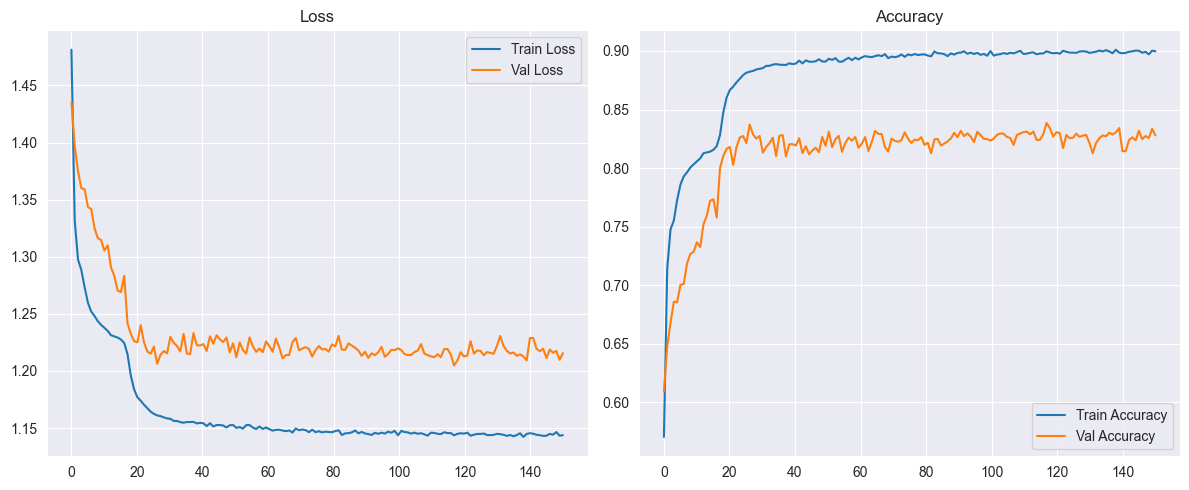

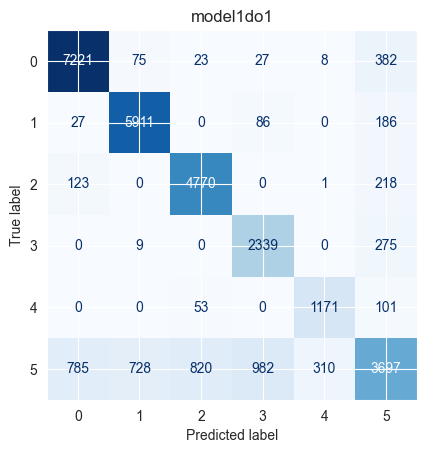

In [12]:
dataset_name = 'ocean'
model_name = 'model1do1'

dataset = ds.Dataset(dataset_name)
X_train, _, _ = dataset.train()
X_val, _, _ = dataset.validation()
X_test, _, _ = dataset.test()
print(X_train.shape, X_val.shape, X_test.shape)

results, acc_train, acc_val = eval_net(dataset_name, model_name, print_report = True, plot_acc = True, plot_conf = True)

# Accuracy comparison

In [27]:
dataset_list = ['adult', 'bank', 'beans', 'cancer', 'heloc', 'mushroom', 'ocean', 'wine']
models_list = ['model1', 'model1do1', 'model1do2', 'model1bn', 'model1r']
models_colors = ['black', 'red', 'pink', 'blue', 'green']

In [23]:
val = True # else the train accuracies are displayed

data = []
for dataset in dataset_list:
    row = [dataset]
    for model in models_list:
        history = joblib.load(f'./models/histories/{dataset}_{model}_history.joblib')
        if val:
            acc = history['val_acc'][-1]
        else:
            acc = history['train_acc'][-1]
        row.append(acc)
    data.append(row)

print('Validation accuracy\n' if val else 'Train accuracy\n')
print(tabulate(data, headers=["Dataset", *models_list], tablefmt="github", floatfmt=".4f"))

Validation accuracy

| Dataset   |   model1 |   model1do1 |   model1do2 |   model1bn |   model1r |
|-----------|----------|-------------|-------------|------------|-----------|
| adult     |   0.8342 |      0.8377 |      0.8399 |     0.8341 |    0.8385 |
| bank      |   0.9045 |      0.9101 |      0.9097 |     0.9081 |    0.9063 |
| beans     |   0.9136 |      0.9204 |      0.9226 |     0.9150 |    0.9177 |
| cancer    |   0.9669 |      0.9669 |      0.9752 |     0.9421 |    0.9587 |
| heloc     |   0.6878 |      0.6947 |      0.6979 |     0.6796 |    0.6903 |
| mushroom  |   1.0000 |      1.0000 |      1.0000 |     1.0000 |    1.0000 |
| ocean     |   0.8258 |      0.8279 |      0.6171 |     0.7747 |    0.7936 |
| wine      |   0.8282 |      0.8218 |      0.8205 |     0.8385 |    0.8462 |


In [24]:
# test accuracy

data = []
for d in dataset_list:
    dataset = ds.Dataset(d)
    _, X, y = dataset.test()
    y_true = y.argmax(dim=1).numpy()
    row = [d]
    for m in models_list:
        model = dataset.load_model(m)
        model.eval()
        with torch.no_grad():
            preds = model(X).argmax(dim=1).numpy()
        row.append(accuracy_score(y_true, preds))
    data.append(row)

print('Test accuracy')
print(tabulate(data, headers=["Dataset", *models_list], tablefmt="github", floatfmt=".4f"))

Test accuracy
| Dataset   |   model1 |   model1do1 |   model1do2 |   model1bn |   model1r |
|-----------|----------|-------------|-------------|------------|-----------|
| adult     |   0.8360 |      0.8370 |      0.8430 |     0.8250 |    0.8380 |
| bank      |   0.9080 |      0.9050 |      0.9160 |     0.9140 |    0.9140 |
| beans     |   0.9120 |      0.9140 |      0.9120 |     0.9120 |    0.9080 |
| cancer    |   0.9200 |      0.9600 |      0.9600 |     0.9200 |    0.9200 |
| heloc     |   0.7260 |      0.7140 |      0.7140 |     0.6780 |    0.7060 |
| mushroom  |   1.0000 |      1.0000 |      1.0000 |     1.0000 |    1.0000 |
| ocean     |   0.8298 |      0.8314 |      0.6173 |     0.7749 |    0.7963 |
| wine      |   0.8550 |      0.8550 |      0.8550 |     0.8650 |    0.8850 |


retrain needed for:
- heloc batchnorm
- ocean dropout 0.2

remarkable (0.2)
- adult 0.2
- bank 0.2

# ROC-AUC scores comparison

In [28]:
results = []
y_vals = []

for dataset in dataset_list:
    ddd = ds.Dataset(dataset)
    _, _, y_val = ddd.validation()
    y_vals.append(y_val)
    res = []
    for model in models_list:
        r = joblib.load(f'./models/results/{dataset}_{model}_results.joblib')
        res.append(r)
    results.append(res)

In [29]:
def ovr_roc(y_onehot, proba):
    if proba.shape[1] == 2:
        y, p = y_onehot[:, 1], proba[:, 1]
    else:
        y, p = y_onehot.ravel(), proba.ravel()
    fpr, tpr, _ = roc_curve(y, p)
    return roc_auc_score(y, p), fpr, tpr

def plot_roc(y_val, results, dataset_name, models_colors, models_list):
    y_onehot = y_val.detach().numpy()
    auc_scores = []

    plt.figure()
    plt.title(dataset_name)
    for i in range(len(results)):
        roc, fpr, tpr = ovr_roc(y_onehot, results[i]['pred_proba'][0])
        plt.plot(fpr, tpr, color=models_colors[i], label=f'{models_list[i]} - {roc:.4f}')
        auc_scores.append(roc)

    plt.plot([0,1],[0,1], color='grey', linestyle='--', label='Random')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend()

    plt.tight_layout()
    plt.show()

    return auc_scores

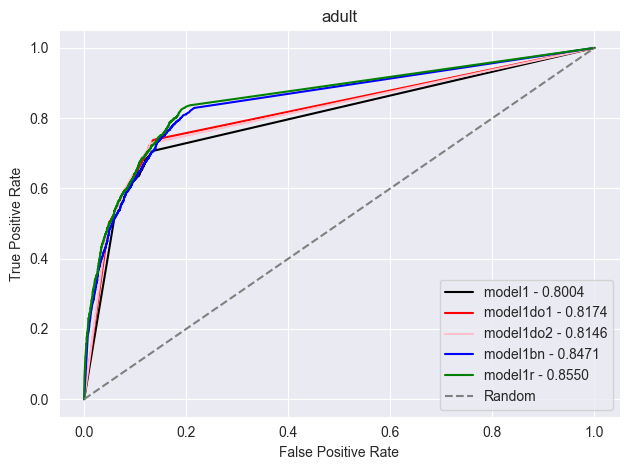

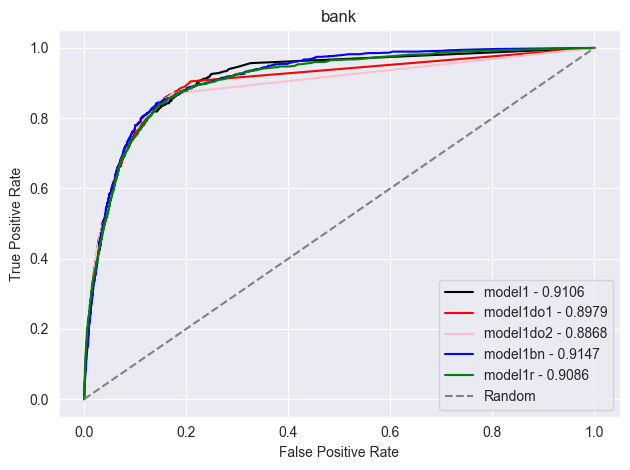

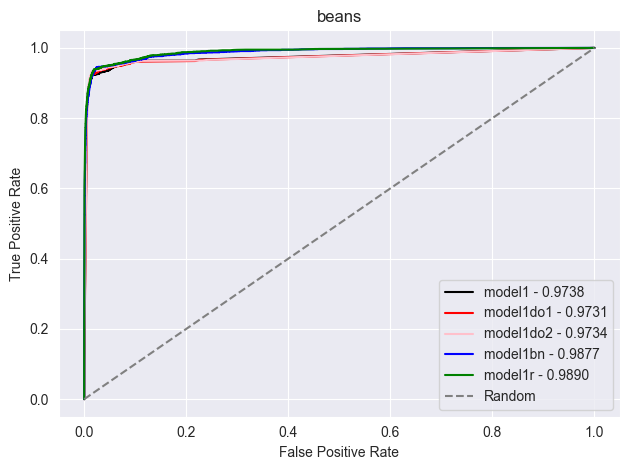

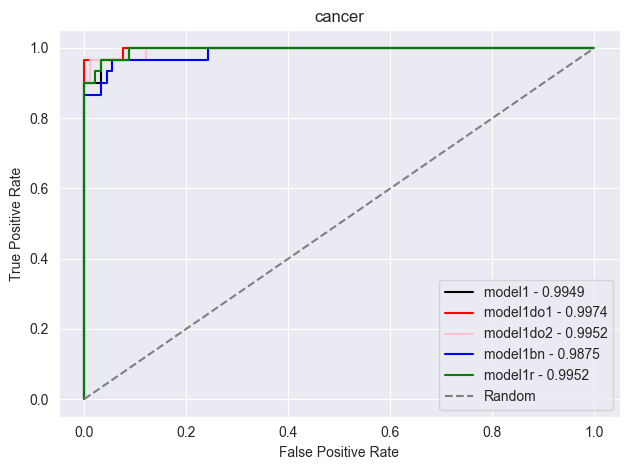

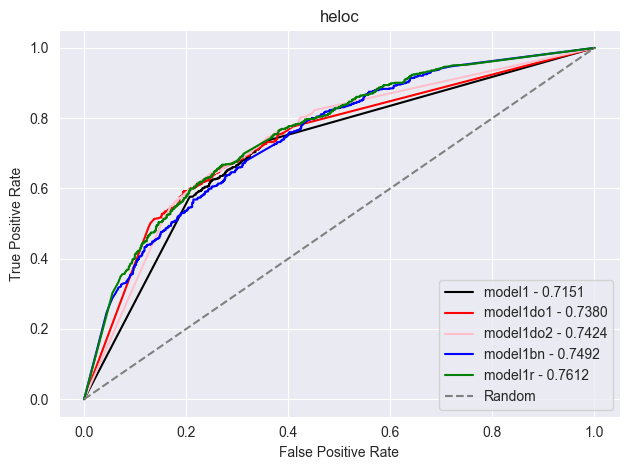

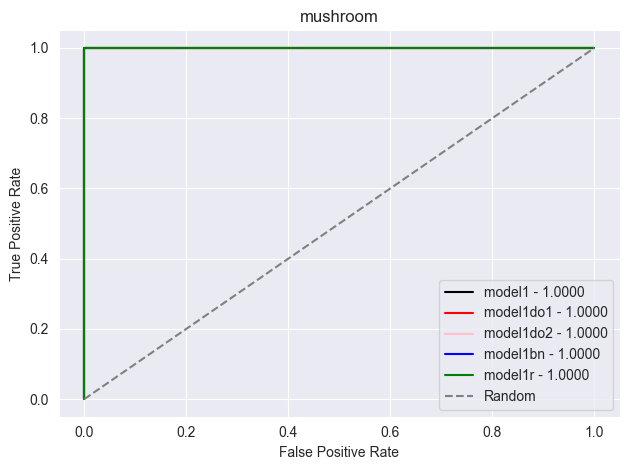

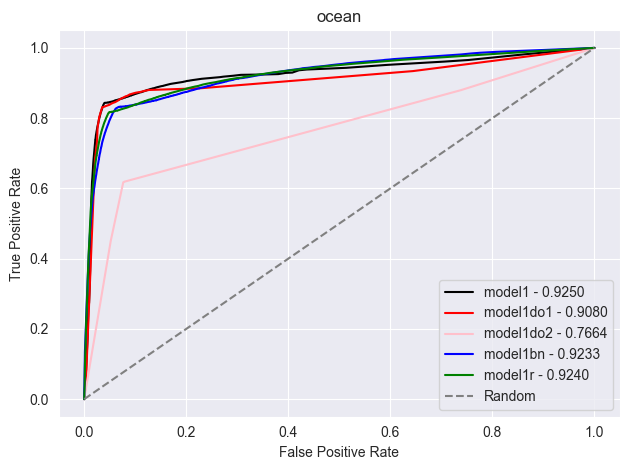

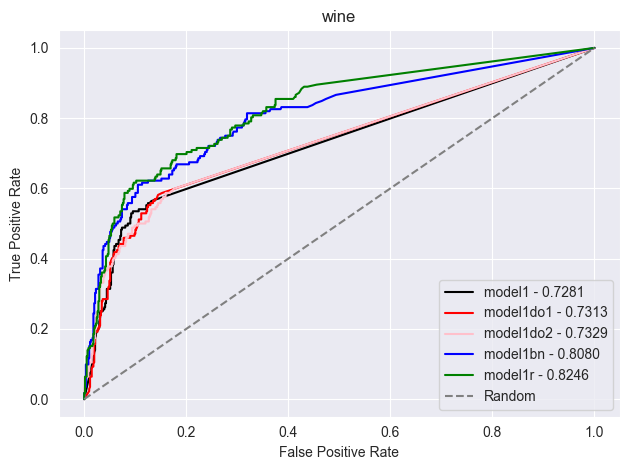

In [30]:
auc_scores = []
for idx, dataset in enumerate(dataset_list):
    auc = plot_roc(y_vals[idx], results[idx], dataset, models_colors, models_list)
    auc_scores.append(auc)

In [32]:
print("AUC score\n")
data = [[name, *scores] for name, scores in zip(dataset_list, auc_scores)]
headers = ["Dataset", *models_list]
print(tabulate(data, headers=headers, tablefmt="github", floatfmt=".4f"))

AUC score

| Dataset   |   model1 |   model1do1 |   model1do2 |   model1bn |   model1r |
|-----------|----------|-------------|-------------|------------|-----------|
| adult     |   0.8004 |      0.8174 |      0.8146 |     0.8471 |    0.8550 |
| bank      |   0.9106 |      0.8979 |      0.8868 |     0.9147 |    0.9086 |
| beans     |   0.9738 |      0.9731 |      0.9734 |     0.9877 |    0.9890 |
| cancer    |   0.9949 |      0.9974 |      0.9952 |     0.9875 |    0.9952 |
| heloc     |   0.7151 |      0.7380 |      0.7424 |     0.7492 |    0.7612 |
| mushroom  |   1.0000 |      1.0000 |      1.0000 |     1.0000 |    1.0000 |
| ocean     |   0.9250 |      0.9080 |      0.7664 |     0.9233 |    0.9240 |
| wine      |   0.7281 |      0.7313 |      0.7329 |     0.8080 |    0.8246 |


retrain needed for:
- ocean dropout 0.2

In [37]:
# test AUCs

data = []
for d in dataset_list:
    dataset = ds.Dataset(d)
    _, X, y = dataset.test()
    y_onehot = y.numpy()
    row = [d]
    for m in models_list:
        model = dataset.load_model(m)
        model.eval()
        with torch.no_grad():
            proba = model(X).numpy()
        auc, _, _ = ovr_roc(y_onehot, proba)
        row.append(auc)
    data.append(row)

print('Test AUC')
print(tabulate(data, headers=["Dataset", *models_list], tablefmt="github", floatfmt=".4f"))

Test AUC
| Dataset   |   model1 |   model1do1 |   model1do2 |   model1bn |   model1r |
|-----------|----------|-------------|-------------|------------|-----------|
| adult     |   0.8502 |      0.8641 |      0.8748 |     0.8868 |    0.8961 |
| bank      |   0.9210 |      0.9155 |      0.9186 |     0.9209 |    0.8953 |
| beans     |   0.9908 |      0.9921 |      0.9893 |     0.9895 |    0.9926 |
| cancer    |   0.9861 |      0.9861 |      0.9878 |     0.9705 |    0.9757 |
| heloc     |   0.7630 |      0.7772 |      0.7763 |     0.7532 |    0.7696 |
| mushroom  |   1.0000 |      1.0000 |      1.0000 |     1.0000 |    1.0000 |
| ocean     |   0.9489 |      0.9394 |      0.7875 |     0.9475 |    0.9480 |
| wine      |   0.8012 |      0.7744 |      0.7718 |     0.8742 |    0.8643 |


# F1 score

In [33]:
# test f1

data = []
for d in dataset_list:
    dataset = ds.Dataset(d)
    _, X, y = dataset.test()
    y_true = y.argmax(dim=1).numpy()
    row = [d]
    for m in models_list:
        model = dataset.load_model(m)
        model.eval()
        with torch.no_grad():
            preds = model(X).argmax(dim=1).numpy()
        row.append(f1_score(y_true, preds, average='macro'))
    data.append(row)

print('Test f1')
print(tabulate(data, headers=["Dataset", *models_list], tablefmt="github", floatfmt=".4f"))

Test f1
| Dataset   |   model1 |   model1do1 |   model1do2 |   model1bn |   model1r |
|-----------|----------|-------------|-------------|------------|-----------|
| adult     |   0.7765 |      0.7756 |      0.7833 |     0.7591 |    0.7754 |
| bank      |   0.7444 |      0.6963 |      0.7436 |     0.7451 |    0.7401 |
| beans     |   0.9241 |      0.9265 |      0.9270 |     0.9252 |    0.9233 |
| cancer    |   0.9151 |      0.9566 |      0.9566 |     0.9151 |    0.9151 |
| heloc     |   0.7255 |      0.7132 |      0.7133 |     0.6773 |    0.7059 |
| mushroom  |   1.0000 |      1.0000 |      1.0000 |     1.0000 |    1.0000 |
| ocean     |   0.8233 |      0.8245 |      0.3783 |     0.7701 |    0.7811 |
| wine      |   0.6943 |      0.6943 |      0.7033 |     0.7316 |    0.7714 |


retrain needed for:
- bank dropout 0.1
- heloc batchnorm
- ocean dropout 0.2